In [4]:
import pandas as pd

df = pd.read_csv("../data/raw/embalses.csv")

print(df.shape)
print(df.dtypes)
df.head()

(723842, 6)
AMBITO_NOMBRE       str
EMBALSE_NOMBRE      str
FECHA               str
AGUA_TOTAL          str
AGUA_ACTUAL         str
ELECTRICO_FLAG    int64
dtype: object


,AMBITO_NOMBRE,EMBALSE_NOMBRE,FECHA,AGUA_TOTAL,AGUA_ACTUAL,ELECTRICO_FLAG
0,Duero,Barrios de Luna,2016-06-14,"308,00","298,00",0
1,Duero,Barrios de Luna,2016-06-21,"308,00","296,00",0
2,Duero,Barrios de Luna,2016-06-28,"308,00","288,00",0
3,Duero,Barrios de Luna,2016-07-05,"308,00","277,00",0
4,Duero,Barrios de Luna,2016-07-12,"308,00","263,00",0


In [5]:
#Pasamos la fecha al tipo correcto. 

df = pd.read_csv(
    "../data/raw/embalses.csv",
    decimal=",",
    parse_dates=["FECHA"],
)

print(df.dtypes)
df.describe()

AMBITO_NOMBRE                str
EMBALSE_NOMBRE               str
FECHA             datetime64[us]
AGUA_TOTAL               float64
AGUA_ACTUAL              float64
ELECTRICO_FLAG             int64
dtype: object


,FECHA,AGUA_TOTAL,AGUA_ACTUAL,ELECTRICO_FLAG
count,723842,723840.000000,723840.000000,723842.000000
mean,2007-08-19 01:31:35.356169,148.773493,84.637989,0.269522
min,1987-10-06 00:00:00,0.000000,0.000000,0.000000
25%,1997-12-09 00:00:00,14.000000,7.000000,0.000000
50%,2007-10-02 00:00:00,38.000000,20.000000,0.000000
75%,2017-05-16 00:00:00,126.000000,69.000000,1.000000
max,2026-10-20 00:00:00,3219.000000,3193.000000,1.000000
std,NaN,350.868919,218.732762,0.443712


In [6]:
# Filas con algún volumen nulo

df[df[["AGUA_TOTAL", "AGUA_ACTUAL"]].isna().any(axis=1)]

,AMBITO_NOMBRE,EMBALSE_NOMBRE,FECHA,AGUA_TOTAL,AGUA_ACTUAL,ELECTRICO_FLAG
573187,Ebro,Pajares,2003-05-13,NaN,NaN,0
573189,Ebro,Pajares,2003-05-27,NaN,NaN,0


In [8]:
#Valores imposibles

print("Capacidad 0:", (df["AGUA_TOTAL"] == 0).sum())
print("Volumen > capacidad:", (df["AGUA_ACTUAL"] > df["AGUA_TOTAL"]).sum())
print("Negativos:", (df["AGUA_ACTUAL"] < 0).sum())

# De qué embalses son las capacidades 0
df[df["AGUA_TOTAL"] == 0]["EMBALSE_NOMBRE"].value_counts()

Capacidad 0: 18960
Volumen > capacidad: 1264
Negativos: 0


EMBALSE_NOMBRE
Vadomojón                583
Agavanzal, Nª Sª de      582
Castro de las Cogotas    582
Aguijón, El              582
Castilseras              582
                        ... 
Crevillente               19
Benínar                   14
Béznar                    14
Jerte - Plasencia         13
Portaje                   13
Name: count, Length: 71, dtype: int64

In [9]:
# ¿Cuándo tiene capacidad 0 Vadomojón y cuándo no?
v = df[df["EMBALSE_NOMBRE"] == "Vadomojón"]
print(v.groupby(v["AGUA_TOTAL"] == 0)["FECHA"].agg(["min", "max"]))

# Volumen > capacidad: ¿cuántos tienen capacidad 0?
sobre = df[df["AGUA_ACTUAL"] > df["AGUA_TOTAL"]]
print("De ellos con capacidad 0:", (sobre["AGUA_TOTAL"] == 0).sum())

                  min        max
AGUA_TOTAL                      
False      1999-03-09 2026-10-20
True       1988-01-05 1999-03-02
De ellos con capacidad 0: 93


In [10]:
#Vamos a buscar como viene escrito Guadalquivir que es el que nos interesa 

df["AMBITO_NOMBRE"].value_counts()

AMBITO_NOMBRE
Ebro                               125127
Guadalquivir                       105192
Tajo                               101698
Guadiana                            70471
Duero                               67870
Miño - Sil                          58725
Júcar                               45435
Segura                              29577
Galicia Costa                       22275
Cuenca Mediterránea Andaluza        21992
Cantábrico Occidental               18226
Cuencas Internas de Cataluña        16680
Guadalete-Barbate                   16200
Tinto, Odiel y Piedras              13377
Cantábrico Oriental                  6947
Cuencas Internas del País Vasco      4050
Name: count, dtype: int64

In [ ]:
#Filtramos por Guadalquivir para ver cuantos son Hidroelectrico (1) y Consuntivo (0) para riego y abastecimiento.

gq = df[df["AMBITO_NOMBRE"] == "Guadalquivir"].copy()

print("Embalses:", gq["EMBALSE_NOMBRE"].nunique())
print(gq.groupby("ELECTRICO_FLAG")["EMBALSE_NOMBRE"].nunique())

Embalses: 62
ELECTRICO_FLAG
0    54
1     8
Name: EMBALSE_NOMBRE, dtype: int64


In [ ]:
#Para ver si hay embalses escritos de dos formas diferentes

sorted(gq["EMBALSE_NOMBRE"].unique())

['Agrio (Aznalcollar)',
 'Aguascebas',
 'Alcalá del Río',
 'Aracena',
 'Arenoso',
 'Bembézar',
 'Bermejales',
 'Bolera, La',
 'Breña II, La',
 'Breña, La',
 'Cala',
 'Canales',
 'Cantillana',
 'Carpio, El',
 'Colomera',
 'Cordobilla',
 'Cubillas',
 'Derivación Retortillo',
 'Doña Aldonza',
 'El Portillo',
 'Encinarejo',
 'Fernandina, La',
 'Francisco Abellán',
 'Fresneda',
 'Gergal',
 'Giribaile',
 'Guadalmellato',
 'Guadalmena',
 'Guadalén',
 'Guillena',
 'Hornachuelos',
 'Huesna',
 'Iznájar',
 'José Torán',
 'Jándula',
 'Malpasillo ( Jauja )',
 'Marmolejo',
 'Martín Gonzalo',
 'Melonares, Los',
 'Minilla, La',
 'Montoro',
 'Negratín',
 'Pedro Marín',
 'Pintado, El',
 'Puebla de Cazalla',
 'Puente Nuevo',
 'Quiebrajano',
 'Quéntar',
 'Retortillo',
 'Rumblar',
 'San Clemente',
 'San Rafael de Navallana',
 'Sierra Boyera',
 'Siles',
 'Torre del Águila',
 'Tranco de Beas',
 'Vadomojón',
 'Villafranca',
 'Víboras',
 'Yeguas',
 'Zocueca',
 'Zufre']

In [ ]:
#Lista completa de embalses y detectar duplicados

print("\n".join(sorted(gq["EMBALSE_NOMBRE"].unique())))

breña = gq[gq["EMBALSE_NOMBRE"].str.contains("Breña")]
breña.groupby("EMBALSE_NOMBRE")["FECHA"].agg(["min", "max"])

Agrio (Aznalcollar)
Aguascebas
Alcalá del Río
Aracena
Arenoso
Bembézar
Bermejales
Bolera, La
Breña II, La
Breña, La
Cala
Canales
Cantillana
Carpio, El
Colomera
Cordobilla
Cubillas
Derivación Retortillo
Doña Aldonza
El Portillo
Encinarejo
Fernandina, La
Francisco Abellán
Fresneda
Gergal
Giribaile
Guadalmellato
Guadalmena
Guadalén
Guillena
Hornachuelos
Huesna
Iznájar
José Torán
Jándula
Malpasillo ( Jauja )
Marmolejo
Martín Gonzalo
Melonares, Los
Minilla, La
Montoro
Negratín
Pedro Marín
Pintado, El
Puebla de Cazalla
Puente Nuevo
Quiebrajano
Quéntar
Retortillo
Rumblar
San Clemente
San Rafael de Navallana
Sierra Boyera
Siles
Torre del Águila
Tranco de Beas
Vadomojón
Villafranca
Víboras
Yeguas
Zocueca
Zufre


,min,max
EMBALSE_NOMBRE,,
"Breña II, La",2009-12-29,2026-10-20
"Breña, La",1988-01-05,2009-12-22


In [14]:
#Calculamos los dias entre fechas consecutivas para comprobar que el dato es semanal y detectar semanas que faltan

fechas = pd.Series(sorted(gq["FECHA"].unique()))
print("Fechas distintas:", len(fechas))
fechas.diff().value_counts()

Fechas distintas: 2025


7 days    2024
Name: count, dtype: int64

In [15]:
#Buscar duplicados

dup = gq.duplicated(subset=["EMBALSE_NOMBRE", "FECHA"], keep=False)
print("Filas duplicadas:", dup.sum())
gq[dup].sort_values(["EMBALSE_NOMBRE", "FECHA"]).head(10)

Filas duplicadas: 0


,AMBITO_NOMBRE,EMBALSE_NOMBRE,FECHA,AGUA_TOTAL,AGUA_ACTUAL,ELECTRICO_FLAG


In [16]:
#Vemos en qué fechas empieza y termina cada embalse con capacidad real para detectar los que entran tarde, se dan de baja o tienen huecos.

activos = gq[gq["AGUA_TOTAL"] > 0]

cobertura = activos.groupby("EMBALSE_NOMBRE").agg(
    inicio=("FECHA", "min"),
    fin=("FECHA", "max"),
    semanas=("FECHA", "count"),
)
cobertura["semanas_esperadas"] = ((cobertura["fin"] - cobertura["inicio"]).dt.days // 7) + 1
cobertura["huecos"] = cobertura["semanas_esperadas"] - cobertura["semanas"]

cobertura.sort_values("inicio")

,inicio,fin,semanas,semanas_esperadas,huecos
EMBALSE_NOMBRE,,,,,
Agrio (Aznalcollar),1988-01-05,2026-10-20,2025,2025,0
Guadalmena,1988-01-05,2026-10-20,2025,2025,0
Guadalén,1988-01-05,2026-10-20,2025,2025,0
Guillena,1988-01-05,2003-05-27,804,804,0
Iznájar,1988-01-05,2026-10-20,2025,2025,0
...,...,...,...,...,...
Arenoso,2008-03-11,2026-10-20,972,972,0
"Breña II, La",2009-12-29,2026-10-20,878,878,0
"Melonares, Los",2010-03-16,2026-10-20,867,867,0


In [ ]:
#Buscamos los embalses que no tineen datos durante el perdiodo de 1988-2026. El hueco nos dice las semanas que faltan.

inicio_total, fin_total = activos["FECHA"].min(), activos["FECHA"].max()

print("Huecos totales:", cobertura["huecos"].sum())
raros = cobertura[(cobertura["inicio"] > inicio_total) | (cobertura["fin"] < fin_total)]
print("Embalses incompletos:", len(raros))
raros.sort_values("inicio")

Huecos totales: 262
Embalses incompletos: 37


,inicio,fin,semanas,semanas_esperadas,huecos
EMBALSE_NOMBRE,,,,,
Guillena,1988-01-05,2003-05-27,804,804,0
Alcalá del Río,1988-01-05,2012-06-26,1278,1278,0
Villafranca,1988-01-05,2008-03-04,1053,1053,0
"Breña, La",1988-01-05,2009-12-22,1147,1147,0
Cantillana,1988-01-05,2012-06-26,1278,1278,0
"Carpio, El",1988-01-05,2012-06-26,1278,1278,0
Cordobilla,1988-01-05,2012-06-19,1277,1277,0
Derivación Retortillo,1988-01-05,2012-06-26,1278,1278,0
Marmolejo,1988-01-05,2012-06-26,1278,1278,0


In [ ]:
#Contamos las capacidades de cada embalse. Aunque a nosotros lo que nos importa para el modelo es el cambio de volumen, y un 
#cambio de capacidad no altera el volumen.

caps = activos.groupby("EMBALSE_NOMBRE")["AGUA_TOTAL"].agg(["nunique", "min", "max"])
caps[caps["nunique"] > 1].sort_values("nunique", ascending=False)

,nunique,min,max
EMBALSE_NOMBRE,,,
Negratín,4,100.0,571.0
Torre del Águila,4,48.0,66.0
Zufre,3,168.0,179.0
Puente Nuevo,3,281.0,286.0
Iznájar,3,920.0,981.0
Guadalmena,3,345.0,347.0
Guadalmellato,3,145.0,162.0
Giribaile,3,5.0,491.0
"Pintado, El",3,202.0,215.0


In [20]:
#Vamos a investigar los embalses de Negratin y Giribaile, ya que se ven raros, para saber si es un error o un cambio real.

for nombre in ["Negratín", "Giribaile"]:
    e = activos[activos["EMBALSE_NOMBRE"] == nombre]
    print(nombre)
    print(e.groupby("AGUA_TOTAL")["FECHA"].agg(["min", "max", "count"]), "\n")

Negratín
                  min        max  count
AGUA_TOTAL                             
100.0      1988-01-05 1988-03-01      9
546.0      1988-03-08 2003-04-22    790
567.0      2003-04-29 2022-09-27   1014
571.0      2022-10-04 2026-10-20    212 

Giribaile
                  min        max  count
AGUA_TOTAL                             
5.0        1994-02-01 1994-03-01      5
475.0      1999-03-09 2022-09-27   1230
491.0      2022-10-04 2026-10-20    212 



Matplotlib is building the font cache; this may take a moment.


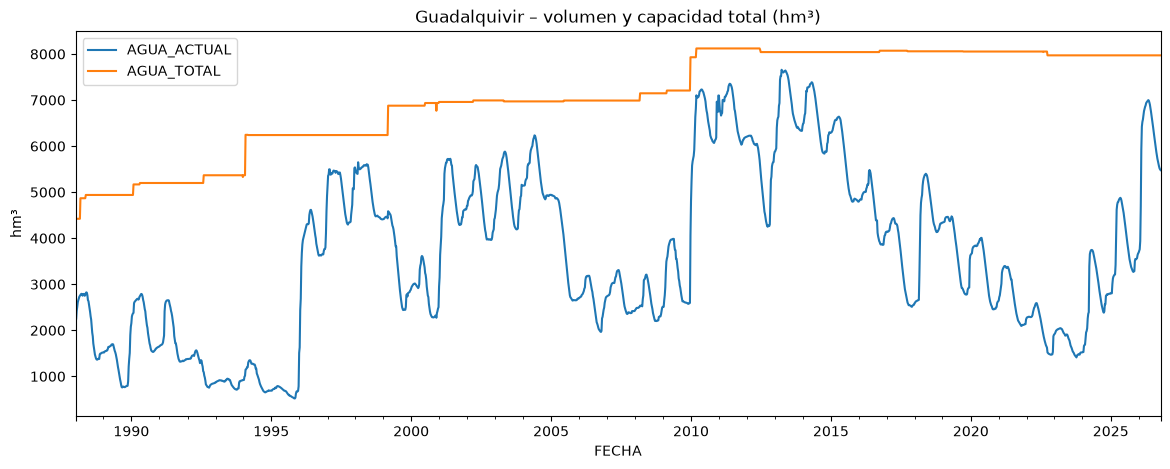

In [21]:
#Primera gráfica: sumamos el volumen por semana para ver su evolucion y los saltos artificiales

import matplotlib.pyplot as plt

consuntivos = activos[activos["ELECTRICO_FLAG"] == 0]
total = consuntivos.groupby("FECHA")[["AGUA_ACTUAL", "AGUA_TOTAL"]].sum()

total.plot(figsize=(14, 5), title="Guadalquivir – volumen y capacidad total (hm³)")
plt.ylabel("hm³")
plt.show()